# Job Application Data Analysis

## Objective
Analyze job application data to identify:
1. Best-performing application sources
2. Relationship between application completion and shortlisting
3. Response-time differences between paid and unpaid roles

Tools: Python, Pandas, Matplotlib

In [ ]:
import pandas as pd

df = pd.read_csv('/content/job-board-applications.csv')

print(df.head())

  application_id  applied_on role_category work_mode  stipend_inr_month  \
0        A100010  2026-07-01      Software   on_site              30000   
1        A100017  2026-07-01        Design    hybrid                  0   
2        A100102  2026-07-01    Operations    hybrid                  0   
3        A100319  2026-07-01     Marketing    remote              15000   
4        A100394  2026-07-01      Software   on_site              10000   

   source  steps_done shortlisted interviewed hired  days_to_first_reply  
0  search           2          no          no    no                  1.0  
1  search           2          no          no    no                  9.0  
2  search           0          no          no    no                  3.0  
3  search           4          no          no    no                  4.0  
4  search           4         yes          no    no                  2.0  


## 1. Data Quality Check

Inspect the dataset to understand its structure, data types, missing values, and duplicate records before performing analysis.

In [ ]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (1206, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   application_id       1206 non-null   object 
 1   applied_on           1206 non-null   object 
 2   role_category        1206 non-null   object 
 3   work_mode            1206 non-null   object 
 4   stipend_inr_month    1206 non-null   int64  
 5   source               1191 non-null   object 
 6   steps_done           1206 non-null   int64  
 7   shortlisted          1206 non-null   object 
 8   interviewed          1206 non-null   object 
 9   hired                1206 non-null   object 
 10  days_to_first_reply  970 non-null    float64
dtypes: float64(1), int64(2), object(8)
memory usage: 103.8+ KB


In [ ]:
print(df.isnull().sum())

application_id           0
applied_on               0
role_category            0
work_mode                0
stipend_inr_month        0
source                  15
steps_done               0
shortlisted              0
interviewed              0
hired                    0
days_to_first_reply    236
dtype: int64


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate application IDs
print("Duplicate IDs:", df["application_id"].duplicated().sum())

Duplicate rows: 6
Duplicate IDs: 6


## 2. Data Cleaning

The dataset was cleaned to ensure consistency and reliability before analysis. Duplicate application IDs were removed, inconsistent work-mode labels were standardized, and the application date column was converted to datetime format.

In [ ]:
# Create a copy of original dataset
df_clean = df.copy()

# Remove duplicate application IDs
df_clean = df_clean.drop_duplicates(
    subset="application_id"
)

# Check rows after cleaning
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Removed duplicates:", len(df) - len(df_clean))

Original rows: 1206
Cleaned rows: 1200
Removed duplicates: 6


In [ ]:
print("Work modes:")
print(df_clean["work_mode"].value_counts())

print("\nSources:")
print(df_clean["source"].value_counts())

print("\nRole categories:")
print(df_clean["role_category"].value_counts())

Work modes:
work_mode
remote     509
hybrid     374
on_site    308
On-site      4
Hybrid       3
Remote       2
Name: count, dtype: int64

Sources:
source
search      439
social      257
college     208
email       160
referral    121
Name: count, dtype: int64

Role categories:
role_category
Software      381
Data          219
Marketing     209
Design        149
Operations    139
Finance       103
Name: count, dtype: int64


In [ ]:
df_clean["work_mode"] = (
    df_clean["work_mode"]
    .str.lower()
    .str.strip()
    .replace({
        "on-site": "on_site"
    })
)

print(df_clean["work_mode"].value_counts())

work_mode
remote     511
hybrid     377
on_site    312
Name: count, dtype: int64


In [ ]:
df_clean["applied_on"] = pd.to_datetime(df_clean["applied_on"])

print(df_clean["applied_on"].dtype)

datetime64[ns]


## 3. Application Source Analysis

Analyze which application sources generate the highest number of hires and compare their hiring conversion rates. Also examine whether source performance varies across different role categories.

In [ ]:
source_analysis = df_clean.groupby("source").agg(
    total_applications=("application_id", "count"),
    total_hires=("hired", lambda x: (x == "yes").sum())
)

print(source_analysis)

          total_applications  total_hires
source                                   
college                  208            7
email                    160           13
referral                 121           13
search                   439           25
social                   257            6


In [ ]:
source_analysis["hire_rate"] = (
    source_analysis["total_hires"] /
    source_analysis["total_applications"] * 100
)

source_analysis["hire_rate"] = source_analysis["hire_rate"].round(2)

print(source_analysis.sort_values(
    "hire_rate", ascending=False
))

          total_applications  total_hires  hire_rate
source                                              
referral                 121           13      10.74
email                    160           13       8.12
search                   439           25       5.69
college                  208            7       3.37
social                   257            6       2.33


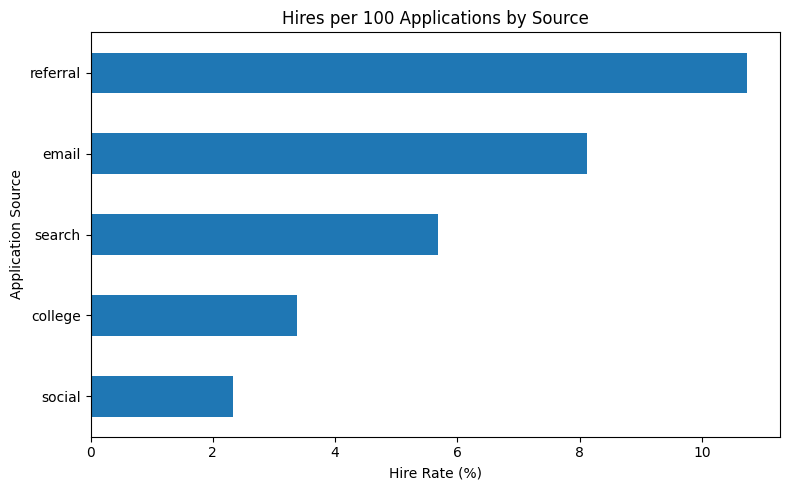

In [ ]:
import matplotlib.pyplot as plt

source_analysis["hire_rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Hires per 100 Applications by Source")
plt.xlabel("Hire Rate (%)")
plt.ylabel("Application Source")
plt.tight_layout()

plt.show()

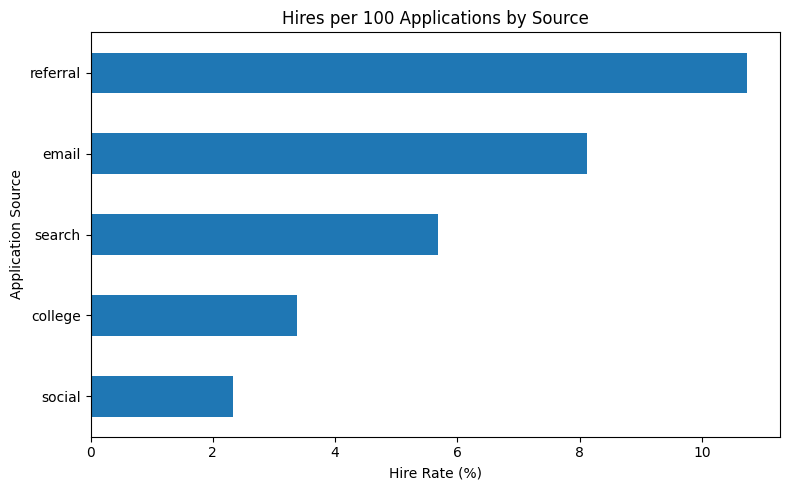

In [ ]:
import matplotlib.pyplot as plt

source_analysis["hire_rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Hires per 100 Applications by Source")
plt.xlabel("Hire Rate (%)")
plt.ylabel("Application Source")
plt.tight_layout()

plt.show()

### Hiring Conversion Rate by Application Source

The chart below compares the hiring conversion rate across different application sources.

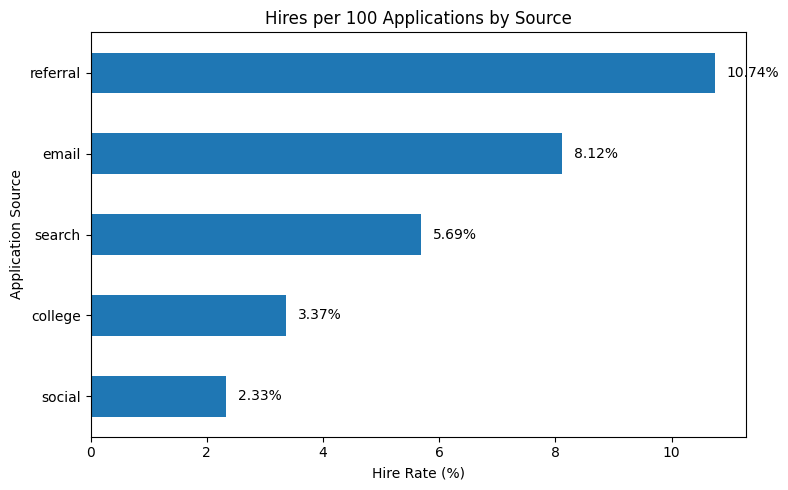

In [ ]:
import matplotlib.pyplot as plt

rates = source_analysis["hire_rate"].sort_values()

ax = rates.plot(kind="barh", figsize=(8, 5))

plt.title("Hires per 100 Applications by Source")
plt.xlabel("Hire Rate (%)")
plt.ylabel("Application Source")

for i, value in enumerate(rates):
    ax.text(value + 0.2, i, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()

### Source Performance by Role Category

Compare hiring conversion rates across application sources within each role category to identify which sources perform best for different types of roles.

## 4. Application Completion & Shortlisting Analysis

Analyze whether applicants who completed all four application steps were shortlisted more frequently than applicants who did not complete all steps. Compare shortlisting rates between the two groups.

In [ ]:
step_analysis = df_clean.groupby(
    df_clean["steps_done"] == 4
).agg(
    total_applications=("application_id", "count"),
    total_shortlisted=("shortlisted", lambda x: (x == "yes").sum())
)

step_analysis.index = ["Incomplete", "Completed 4 Steps"]

print(step_analysis)

                   total_applications  total_shortlisted
Incomplete                        797                 74
Completed 4 Steps                 403                195


In [ ]:
step_analysis["shortlist_rate"] = (
    step_analysis["total_shortlisted"] /
    step_analysis["total_applications"] * 100
)

step_analysis["shortlist_rate"] = (
    step_analysis["shortlist_rate"].round(2)
)

print(step_analysis)

                   total_applications  total_shortlisted  shortlist_rate
Incomplete                        797                 74            9.28
Completed 4 Steps                 403                195           48.39


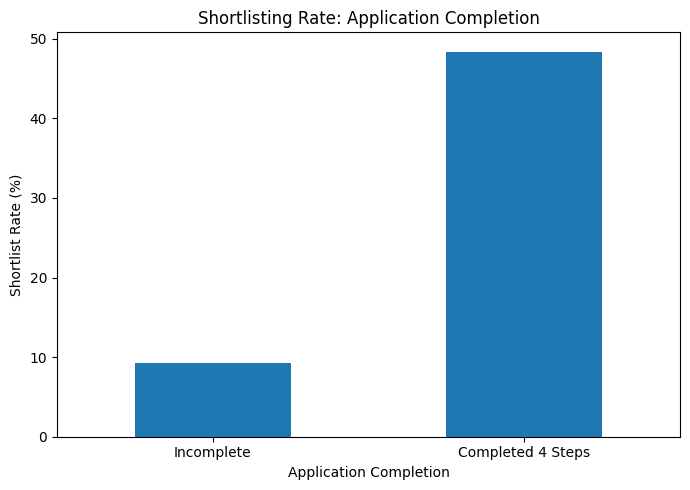

In [ ]:
import matplotlib.pyplot as plt

step_analysis["shortlist_rate"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Shortlisting Rate: Application Completion")
plt.ylabel("Shortlist Rate (%)")
plt.xlabel("Application Completion")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Shortlisting Rate by Application Completion

The chart compares the percentage of applicants shortlisted among those who completed all four application steps and those who did not.

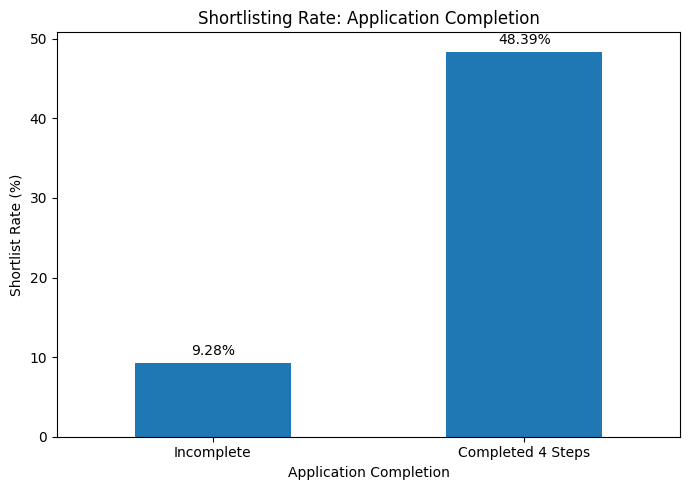

In [ ]:
import matplotlib.pyplot as plt

rates = step_analysis["shortlist_rate"]

ax = rates.plot(kind="bar", figsize=(7, 5))

plt.title("Shortlisting Rate: Application Completion")
plt.ylabel("Shortlist Rate (%)")
plt.xlabel("Application Completion")
plt.xticks(rotation=0)

for i, value in enumerate(rates):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

## 5. Paid vs Unpaid Roles – Response Time Analysis

Compare response times and response rates between paid and unpaid job applications. Evaluate whether paid roles receive faster responses and whether the difference suggests an opportunity to improve applicant communication.

In [ ]:
df_clean["payment_status"] = df_clean["stipend_inr_month"].apply(
    lambda x: "Paid" if x > 0 else "Unpaid"
)

print(df_clean["payment_status"].value_counts())

payment_status
Paid      734
Unpaid    466
Name: count, dtype: int64


In [ ]:
reply_analysis = df_clean.groupby("payment_status").agg(
    total_applications=("application_id", "count"),
    replies_received=("days_to_first_reply", "count"),
    average_reply_days=("days_to_first_reply", "mean"),
    median_reply_days=("days_to_first_reply", "median")
)

reply_analysis["reply_rate"] = (
    reply_analysis["replies_received"] /
    reply_analysis["total_applications"] * 100
)

print(reply_analysis.round(2))

                total_applications  replies_received  average_reply_days  \
payment_status                                                             
Paid                           734               638                3.22   
Unpaid                         466               328                7.62   

                median_reply_days  reply_rate  
payment_status                                 
Paid                          3.0       86.92  
Unpaid                        7.0       70.39  


### Response Time Comparison

Compare average and median response times and the percentage of applications with recorded response times across paid and unpaid roles.

In [ ]:
avg_difference = (
    reply_analysis.loc["Unpaid", "average_reply_days"]
    - reply_analysis.loc["Paid", "average_reply_days"]
)

reply_rate_difference = (
    reply_analysis.loc["Paid", "reply_rate"]
    - reply_analysis.loc["Unpaid", "reply_rate"]
)

print(f"Average response time difference: {avg_difference:.2f} days")
print(f"Reply rate difference: {reply_rate_difference:.2f} percentage points")

Average response time difference: 4.40 days
Reply rate difference: 16.53 percentage points


### Key Findings

Paid applications received a response in an average of 3.22 days, compared with 7.62 days for unpaid applications. This represents a 4.40-day difference.

The recorded reply rate was also higher for paid applications (86.92%) than unpaid applications (70.39%), a difference of 16.53 percentage points.

These findings suggest that unpaid applications may benefit from improved response-time management and communication.

### Average Response Time by Payment Status

The chart compares the average response time for paid and unpaid applications, highlighting the difference in employer responsiveness.

# 6. Key Findings, Recommendations & Limitations

## Key Findings

- **Application Sources:** Referrals had the highest hiring conversion rate (10.74%), followed by Email (8.12%). Search generated the highest number of hires (25), while Social had the lowest conversion rate (2.33%).

- **Application Completion:** Applicants who completed all four steps had a shortlist rate of 48.39%, compared with 9.28% for incomplete applications — a difference of 39.11 percentage points.

- **Paid vs. Unpaid Roles:** Paid applications had a faster average response time (3.22 days) than unpaid applications (7.62 days). Paid applications also had a higher recorded reply rate (86.92% vs. 70.39%).

## Recommendations

1. Prioritize referral sourcing while reviewing the effectiveness of social recruiting.
2. Encourage applicants to complete all four application steps through reminders and a simpler application process.
3. Improve communication and response-time management for unpaid applications.

## Limitations

- 6 duplicate application records were removed.
- 15 applications had missing source information.
- 236 applications had missing response-time data.
- The relationship between application completion and shortlisting does not establish causation.
- Source performance may vary across role categories, and some category-source combinations may have small sample sizes.